# Project 2
Market-basket analysis of actor co-occurrence in the IMDB Top 1000


Parsa Hajiannejad - 48891A

## 0. Global settings

In [18]:
# ---- Global settings (the only cell you need to touch) ----
SUBSAMPLE = False      # True -> work on the first N_SUB movies only
N_SUB = 200            # number of movies kept when SUBSAMPLE is True

MIN_SUPPORT = 3        # absolute support threshold: an itemset is frequent if it occurs in >= MIN_SUPPORT movies
MAX_K = 3              # largest itemset size explored (1 = singletons, 2 = pairs, 3 = triples)
NUM_PARTITIONS = 4     # number of chunks the baskets are split into for SON on Spark

STAR_COLS = ["Star1", "Star2", "Star3", "Star4"]
KAGGLE_DATASET = "harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows"
CSV_NAME = "imdb_top_1000.csv"

## 1. Downloading the dataset (Kaggle API)

In [19]:
import os

if not os.path.exists(CSV_NAME):
    os.environ["KAGGLE_API_TOKEN"] = "KGAT_e65aeaf40a4ebd84a2ec06f5152d443c"      # <-- your Kaggle token here (blank before committing!)
    !pip install -q -U kaggle
    !kaggle datasets download -d {KAGGLE_DATASET}
    !unzip -o -q *.zip

print("dataset available:", os.path.exists(CSV_NAME))

dataset available: True


## 2. Load and inspect

In [20]:
import pandas as pd

df = pd.read_csv(CSV_NAME)
if SUBSAMPLE:
    df = df.head(N_SUB)

print("movies (rows):", df.shape[0], " columns:", df.shape[1])
print("columns:", list(df.columns))
print("missing values in star columns:", df[STAR_COLS].isna().sum().to_dict())
df[["Series_Title"] + STAR_COLS].head()

movies (rows): 1000  columns: 16
columns: ['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate', 'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director', 'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross']
missing values in star columns: {'Star1': 0, 'Star2': 0, 'Star3': 0, 'Star4': 0}


,Series_Title,Star1,Star2,Star3,Star4
0,The Shawshank Redemption,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler
1,The Godfather,Marlon Brando,Al Pacino,James Caan,Diane Keaton
2,The Dark Knight,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine
3,The Godfather: Part II,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton
4,12 Angry Men,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler


## 3. Pre-processing
rows -> baskets


In [21]:
from collections import Counter

def build_baskets(dataframe, star_cols=STAR_COLS):
    baskets = []
    for _, row in dataframe.iterrows():
        actors = set()
        for col in star_cols:
            name = row[col]
            if pd.notna(name):
                name = str(name).strip()
                if name:
                    actors.add(name)
        baskets.append(frozenset(actors))
    return baskets

baskets = build_baskets(df)

actor_counts = Counter()
for b in baskets:
    actor_counts.update(b)

print("baskets:", len(baskets))
print("distinct actors (items):", len(actor_counts))
print("basket sizes:", dict(Counter(len(b) for b in baskets)))
print("actors appearing in exactly one movie:", sum(1 for c in actor_counts.values() if c == 1))
print("actors appearing in >= %d movies:" % MIN_SUPPORT, sum(1 for c in actor_counts.values() if c >= MIN_SUPPORT))

top10 = pd.DataFrame(actor_counts.most_common(10), columns=["actor", "movies"])
top10

baskets: 1000
distinct actors (items): 2709
basket sizes: {4: 996, 3: 4}
actors appearing in exactly one movie: 2068
actors appearing in >= 3 movies: 271


,actor,movies
0,Robert De Niro,17
1,Tom Hanks,14
2,Al Pacino,13
3,Brad Pitt,12
4,Clint Eastwood,12
5,Christian Bale,11
6,Leonardo DiCaprio,11
7,Matt Damon,11
8,James Stewart,10
9,Michael Caine,9




*   Item distribution : extremely skewed
*   majority of actors appear only in one movie but some appear in more than 10
*   A-Priori's first pass prunes most of the item space



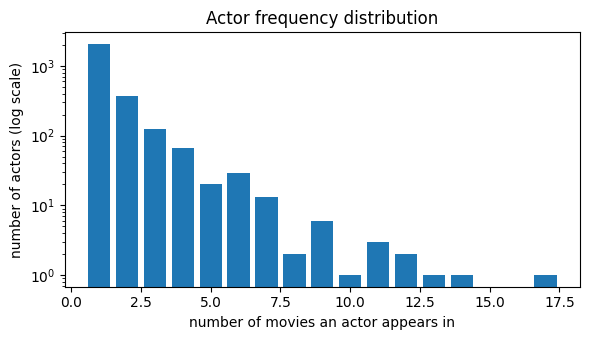

In [22]:
import matplotlib.pyplot as plt

freq_of_freq = Counter(actor_counts.values())          # how many actors appear in exactly c movies
xs = sorted(freq_of_freq)
plt.figure(figsize=(6, 3.5))
plt.bar(xs, [freq_of_freq[x] for x in xs])
plt.yscale("log")
plt.xlabel("number of movies an actor appears in")
plt.ylabel("number of actors (log scale)")
plt.title("Actor frequency distribution")
plt.tight_layout()
plt.show()

## 4. A-Priori implementation (single machine)

In [23]:
from itertools import combinations

def count_singletons(baskets):
    counts = Counter()
    for b in baskets:
        counts.update(b)
    return counts

def count_k_itemsets(baskets, frequent_items, frequent_prev, k):
    # Pass k of A-Priori. A k-subset of a basket gets a counter only if it survives the prune step:
    # all its items are frequent and (for k > 2) all its (k-1)-subsets are frequent.
    # Candidates are tested on the fly, basket by basket, instead of being materialised: with 4-item
    # baskets this costs at most C(4,k) subset checks per basket and keeps memory proportional to the
    # number of candidate itemsets that actually occur (the "triples" representation).
    counts = Counter()
    for b in baskets:
        kept = [item for item in b if item in frequent_items]
        if len(kept) < k:
            continue
        for combo in combinations(sorted(kept), k):
            if k > 2 and not all(frozenset(sub) in frequent_prev for sub in combinations(combo, k - 1)):
                continue
            counts[frozenset(combo)] += 1
    return counts

def apriori(baskets, min_support, max_k=3, verbose=False):
    # Returns {k: {itemset: count}} with the frequent itemsets of every size up to max_k.
    result = {}
    singles = count_singletons(baskets)
    frequent_items = {item for item, c in singles.items() if c >= min_support}
    frequent = {frozenset([item]): c for item, c in singles.items() if c >= min_support}
    result[1] = frequent
    if verbose:
        print(f"pass 1: {len(singles)} items counted -> {len(frequent)} frequent")
    k = 2
    while frequent and k <= max_k:
        counts = count_k_itemsets(baskets, frequent_items, frequent, k)
        frequent = {fs: c for fs, c in counts.items() if c >= min_support}
        result[k] = frequent
        if verbose:
            print(f"pass {k}: {len(counts)} candidate {k}-itemsets counted -> {len(frequent)} frequent")
        k += 1
    return result

def itemsets_table(frequent_k, top=None):
    rows = sorted(((" + ".join(sorted(fs)), c) for fs, c in frequent_k.items()), key=lambda r: (-r[1], r[0]))
    if top:
        rows = rows[:top]
    return pd.DataFrame(rows, columns=["itemset", "support"])

### 4.1 Run the baseline on the full dataset

In [24]:
import time

t0 = time.perf_counter()
baseline = apriori(baskets, MIN_SUPPORT, MAX_K, verbose=True)
baseline_time = time.perf_counter() - t0
print(f"\nA-Priori baseline: {baseline_time:.3f} s")

print("\nFrequent pairs (support >= %d):" % MIN_SUPPORT)
display(itemsets_table(baseline.get(2, {})))
print("Frequent triples (support >= %d):" % MIN_SUPPORT)
display(itemsets_table(baseline.get(3, {})))

pass 1: 2709 items counted -> 271 frequent
pass 2: 622 candidate 2-itemsets counted -> 25 frequent
pass 3: 4 candidate 3-itemsets counted -> 3 frequent

A-Priori baseline: 0.008 s

Frequent pairs (support >= 3):


,itemset,support
0,Daniel Radcliffe + Rupert Grint,6
1,Daniel Radcliffe + Emma Watson,5
2,Emma Watson + Rupert Grint,5
3,Joe Pesci + Robert De Niro,4
4,Tim Allen + Tom Hanks,4
5,Al Pacino + Diane Keaton,3
6,Al Pacino + Robert De Niro,3
7,Carrie Fisher + Harrison Ford,3
8,Carrie Fisher + Mark Hamill,3
9,Chris Evans + Joe Russo,3


Frequent triples (support >= 3):


,itemset,support
0,Daniel Radcliffe + Emma Watson + Rupert Grint,5
1,Carrie Fisher + Harrison Ford + Mark Hamill,3
2,Elijah Wood + Ian McKellen + Orlando Bloom,3


### 4.2 Correctness check against brute force

In [25]:
def brute_force(baskets, min_support, max_k=3):
    result = {}
    for k in range(1, max_k + 1):
        counts = Counter()
        for b in baskets:
            for combo in combinations(sorted(b), k):
                counts[frozenset(combo)] += 1
        result[k] = {fs: c for fs, c in counts.items() if c >= min_support}
        print(f"size {k}: {len(counts)} distinct itemsets counted by brute force")
    return result

bf = brute_force(baskets, MIN_SUPPORT, MAX_K)
for k in range(1, MAX_K + 1):
    assert baseline.get(k, {}) == bf.get(k, {}), f"mismatch at k={k}"
print("OK: A-Priori and brute force agree for all itemset sizes")

size 1: 2709 distinct itemsets counted by brute force
size 2: 5833 distinct itemsets counted by brute force
size 3: 3958 distinct itemsets counted by brute force
OK: A-Priori and brute force agree for all itemset sizes


## 5. SON on Apache Spark


In [26]:
try:
    import pyspark
except ImportError:
    !pip install -q pyspark
    import pyspark

from pyspark import SparkConf, SparkContext

conf = (SparkConf()
        .setAppName("SON-IMDB-actors")
        .setMaster("local[*]")
        .set("spark.driver.memory", "1g")
        .set("spark.ui.showConsoleProgress", "false"))
sc = SparkContext.getOrCreate(conf=conf)
sc.setLogLevel("ERROR")
print("Spark", sc.version, "- cores available:", sc.defaultParallelism)

Spark 4.0.5 - cores available: 2


In [27]:
def son(sc, baskets_rdd, n_total, min_support, max_k=3, verbose=False, stats=None):
    # baskets_rdd: RDD of frozensets. n_total: number of baskets (needed to scale the threshold per chunk).
    # ---- Round 1: local A-Priori in every partition with threshold p*s ----
    def round1(partition):
        chunk = list(partition)
        if not chunk:
            return iter([])
        local_s = min_support * len(chunk) / n_total       # p * s, where p = fraction of baskets in this chunk
        local = apriori(chunk, local_s, max_k)
        return iter(fs for frequent_k in local.values() for fs in frequent_k)

    candidates = baskets_rdd.mapPartitions(round1).distinct().collect()
    cand_by_k = {}
    for fs in candidates:
        cand_by_k.setdefault(len(fs), set()).add(fs)
    if stats is not None:
        stats["candidates"] = {k: len(v) for k, v in sorted(cand_by_k.items())}
    if verbose:
        print("round 1 candidates:", {k: len(v) for k, v in sorted(cand_by_k.items())})

    # ---- Round 2: count every candidate over all baskets ----
    bc = sc.broadcast(cand_by_k)

    def round2(basket):
        out = []
        for k, cset in bc.value.items():
            if len(basket) >= k:
                for combo in combinations(sorted(basket), k):
                    fs = frozenset(combo)
                    if fs in cset:
                        out.append((fs, 1))
        return out

    frequent = (baskets_rdd.flatMap(round2)
                           .reduceByKey(lambda a, b: a + b)
                           .filter(lambda kv: kv[1] >= min_support)
                           .collect())
    result = {}
    for fs, c in frequent:
        result.setdefault(len(fs), {})[fs] = c
    if verbose:
        print("round 2 frequent:", {k: len(v) for k, v in sorted(result.items())})
    return result

### 5.1 Run SON on the real data, read from a file

In [28]:
BASKETS_FILE = "baskets.txt"
with open(BASKETS_FILE, "w", encoding="utf-8") as f:
    for b in baskets:
        f.write("|".join(sorted(b)) + "\n")

baskets_rdd = (sc.textFile(BASKETS_FILE, minPartitions=NUM_PARTITIONS)
                 .map(lambda line: frozenset(line.split("|")))
                 .cache())
n_total = baskets_rdd.count()
print("baskets in RDD:", n_total, "- partitions:", baskets_rdd.getNumPartitions())

t0 = time.perf_counter()
son_result = son(sc, baskets_rdd, n_total, MIN_SUPPORT, MAX_K, verbose=True)
son_time = time.perf_counter() - t0
print(f"\nSON on Spark: {son_time:.3f} s")
display(itemsets_table(son_result.get(2, {})))

baskets in RDD: 1000 - partitions: 4
round 1 candidates: {1: 2709, 2: 5833, 3: 3958}
round 2 frequent: {1: 271, 2: 25, 3: 3}

SON on Spark: 1.517 s


,itemset,support
0,Daniel Radcliffe + Rupert Grint,6
1,Daniel Radcliffe + Emma Watson,5
2,Emma Watson + Rupert Grint,5
3,Joe Pesci + Robert De Niro,4
4,Tim Allen + Tom Hanks,4
5,Al Pacino + Diane Keaton,3
6,Al Pacino + Robert De Niro,3
7,Carrie Fisher + Harrison Ford,3
8,Carrie Fisher + Mark Hamill,3
9,Chris Evans + Joe Russo,3


### 5.2 SON must agree with the single-machine baseline

In [29]:
for k in range(1, MAX_K + 1):
    assert son_result.get(k, {}) == baseline.get(k, {}), f"mismatch at k={k}"
print("OK: SON on Spark and single-machine A-Priori return identical frequent itemsets and counts")

OK: SON on Spark and single-machine A-Priori return identical frequent itemsets and counts


## 6. Experiments

### 6.1 Effect of the support threshold

In [30]:
rows = []
for s in [2, 3, 4, 5, 6, 8]:
    t0 = time.perf_counter(); res_b = apriori(baskets, s, MAX_K); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); res_s = son(sc, baskets_rdd, n_total, s, MAX_K); ts = time.perf_counter() - t0
    assert all(res_b.get(k, {}) == res_s.get(k, {}) for k in range(1, MAX_K + 1))
    rows.append({"support": s,
                 "frequent actors": len(res_b.get(1, {})),
                 "frequent pairs": len(res_b.get(2, {})),
                 "frequent triples": len(res_b.get(3, {})),
                 "A-Priori time (s)": round(tb, 3),
                 "SON time (s)": round(ts, 3)})
threshold_table = pd.DataFrame(rows)
threshold_table

,support,frequent actors,frequent pairs,frequent triples,A-Priori time (s),SON time (s)
0,2,641,121,25,0.010,2.267
1,3,271,25,3,0.050,2.243
2,4,145,5,1,0.012,1.089
3,5,79,3,1,0.004,0.709
4,6,59,1,0,0.005,0.737
5,8,17,0,0,0.007,0.679


### 6.2 Scaling the number of baskets


In [31]:
import random

def replicate(baskets, m, seed=42):
    big = list(baskets) * m
    random.Random(seed).shuffle(big)
    return big

rows = []
for m in [1, 10, 100, 500]:
    big = replicate(baskets, m)
    s = MIN_SUPPORT * m
    t0 = time.perf_counter(); res_b = apriori(big, s, MAX_K); tb = time.perf_counter() - t0
    big_rdd = sc.parallelize(big, NUM_PARTITIONS).cache()
    n_big = big_rdd.count()
    st = {}
    t0 = time.perf_counter(); res_s = son(sc, big_rdd, n_big, s, MAX_K, stats=st); ts = time.perf_counter() - t0
    big_rdd.unpersist()
    expected = {k: {fs: c * m for fs, c in baseline.get(k, {}).items()} for k in range(1, MAX_K + 1)}
    assert all(res_b.get(k, {}) == expected[k] == res_s.get(k, {}) for k in range(1, MAX_K + 1))
    rows.append({"copies": m, "baskets": n_big, "support": s,
                 "SON round-1 candidate pairs": st["candidates"].get(2, 0),
                 "frequent pairs": len(res_s.get(2, {})),
                 "A-Priori time (s)": round(tb, 2), "SON time (s)": round(ts, 2)})
    print(rows[-1])
scaling_table = pd.DataFrame(rows)
scaling_table

{'copies': 1, 'baskets': 1000, 'support': 3, 'SON round-1 candidate pairs': 5833, 'frequent pairs': 25, 'A-Priori time (s)': 0.0, 'SON time (s)': 1.18}
{'copies': 10, 'baskets': 10000, 'support': 30, 'SON round-1 candidate pairs': 67, 'frequent pairs': 25, 'A-Priori time (s)': 0.06, 'SON time (s)': 0.68}
{'copies': 100, 'baskets': 100000, 'support': 300, 'SON round-1 candidate pairs': 25, 'frequent pairs': 25, 'A-Priori time (s)': 0.3, 'SON time (s)': 1.79}
{'copies': 500, 'baskets': 500000, 'support': 1500, 'SON round-1 candidate pairs': 25, 'frequent pairs': 25, 'A-Priori time (s)': 1.49, 'SON time (s)': 7.12}


,copies,baskets,support,SON round-1 candidate pairs,frequent pairs,A-Priori time (s),SON time (s)
0,1,1000,3,5833,25,0.00,1.18
1,10,10000,30,67,25,0.06,0.68
2,100,100000,300,25,25,0.30,1.79
3,500,500000,1500,25,25,1.49,7.12


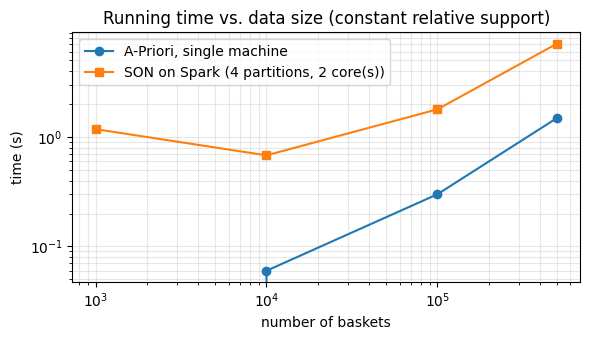

In [32]:
plt.figure(figsize=(6, 3.5))
plt.plot(scaling_table["baskets"], scaling_table["A-Priori time (s)"], "o-", label="A-Priori, single machine")
plt.plot(scaling_table["baskets"], scaling_table["SON time (s)"], "s-", label=f"SON on Spark ({NUM_PARTITIONS} partitions, {sc.defaultParallelism} core(s))")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("number of baskets"); plt.ylabel("time (s)")
plt.title("Running time vs. data size (constant relative support)")
plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

### 6.3 Number of partitions (chunks)

In [33]:
M = 100
big = replicate(baskets, M)
s = MIN_SUPPORT * M
rows = []
for parts in [1, 2, 4, 8, 16]:
    big_rdd = sc.parallelize(big, parts).cache()
    n_big = big_rdd.count()
    st = {}
    t0 = time.perf_counter(); res_s = son(sc, big_rdd, n_big, s, MAX_K, stats=st); ts = time.perf_counter() - t0
    big_rdd.unpersist()
    rows.append({"partitions": parts, "baskets per chunk": n_big // parts, "local threshold p*s": round(s / parts, 2),
                 "round-1 candidates": sum(st["candidates"].values()),
                 "frequent itemsets": sum(len(v) for v in res_s.values()), "SON time (s)": round(ts, 2)})
    print(rows[-1])
partition_table = pd.DataFrame(rows)
partition_table

{'partitions': 1, 'baskets per chunk': 100000, 'local threshold p*s': 300.0, 'round-1 candidates': 299, 'frequent itemsets': 299, 'SON time (s)': 1.59}
{'partitions': 2, 'baskets per chunk': 50000, 'local threshold p*s': 150.0, 'round-1 candidates': 299, 'frequent itemsets': 299, 'SON time (s)': 1.32}
{'partitions': 4, 'baskets per chunk': 25000, 'local threshold p*s': 75.0, 'round-1 candidates': 299, 'frequent itemsets': 299, 'SON time (s)': 1.59}
{'partitions': 8, 'baskets per chunk': 12500, 'local threshold p*s': 37.5, 'round-1 candidates': 324, 'frequent itemsets': 299, 'SON time (s)': 3.49}
{'partitions': 16, 'baskets per chunk': 6250, 'local threshold p*s': 18.75, 'round-1 candidates': 573, 'frequent itemsets': 299, 'SON time (s)': 3.52}


,partitions,baskets per chunk,local threshold p*s,round-1 candidates,frequent itemsets,SON time (s)
0,1,100000,300.00,299,299,1.59
1,2,50000,150.00,299,299,1.32
2,4,25000,75.00,299,299,1.59
3,8,12500,37.50,324,299,3.49
4,16,6250,18.75,573,299,3.52


## 7. Discussion and notes for the report

* **Data organization.** For this project, 1,000 "baskets" (or movies) were analyzed, and exactly 4 actors were assigned to each, resulting in about 2,700 distinct actors total. Interestingly, it was observed that about 75% of them are featured in just a single movie. Because the groups are so small and the data is heavily skewed, most of the actors are quickly eliminated by the first pass of the A-Priori algorithm. Consequently, frequent pairs are rarely found, even when the requirement is set quite low.

* **Memory.** To save memory, the pair counters were stored in a hash table (which is referred to as the "triples" method in class). Since a maximum of only 6 pairs can be created from 4 actors in a movie, the number of pairs that actually occur is dwarfed by the total possible combinations. If a large grid (a triangular matrix) had been built to track everything, it would mostly be filled with empty zeros, and a significant amount of memory would be wasted.

* **Scalability.** The SON algorithm was utilized because only one "chunk" of data needs to be held in an executor's memory at a time. The process is easily scaled as the data grows, and the entire dataset only needs to be read through twice. If the program is run on just one standard laptop, it is unfortunately slowed down by Spark's background overhead (as seen in section 6.2). However, significant improvements are noticed when the data is divided up and processed by multiple computers in parallel.

* **Trade-off in the number of chunks.** A careful balance must be found when deciding how the data is divided. If the chunks are made too small, the threshold for what is considered "frequent" is lowered so much that many false positives are generated in the first round, which then must be heavily processed in round two (see section 6.3). On the other hand, heavier computational tasks are caused by larger chunks. If the mathematical limit (p·s) is allowed to drop below 1, every combination is automatically flagged as a candidate, and the algorithm is essentially reduced to a basic brute-force counting method.
* **Limits.** Because only 1,000 movies were evaluated, the final results are largely dominated by very famous acting duos and trios. Ultimately, this report was prepared so that the code and the mathematical concepts could be successfully demonstrated, rather than expecting that statistically significant patterns in the film industry would be discovered.

In [34]:
sc.stop()
print("done")

done
